In [1]:
import os
import numpy as np
os.environ["KERAS_BACKEND"] = "jax"
import keras
from keras import layers
from datasets import load_dataset


In [2]:
dataset = load_dataset("zalando-datasets/fashion_mnist")
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 60000
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 10000
    })
})


In [3]:

print(dataset["train"]["label"])
# print(dataset["train"].features)
# print(dataset["train"][0])
x = np.array(dataset["train"]["label"])
print(x.shape)
print(x.dtype)
print(x.min())
print(x.max())

Column([9, 0, 0, 3, 0, ...])
(60000,)
int64
0
9


In [4]:

print(dataset["train"]["image"])
# print(dataset["train"].features)
# print(dataset["train"][0])
x = np.array(dataset["train"]["image"])
print(x.shape)
print(x.dtype)
print(x.min())
print(x.max())

Column([<PIL.PngImagePlugin.PngImageFile image mode=L size=28x28 at 0x112B73BC0>, <PIL.PngImagePlugin.PngImageFile image mode=L size=28x28 at 0x169288FE0>, <PIL.PngImagePlugin.PngImageFile image mode=L size=28x28 at 0x1692CC290>, <PIL.PngImagePlugin.PngImageFile image mode=L size=28x28 at 0x1694BE8D0>, <PIL.PngImagePlugin.PngImageFile image mode=L size=28x28 at 0x169546030>, ...])
(60000, 28, 28)
uint8
0
255


Formattazione dei samples

In [5]:
# Creo un tensore train_image con le immagini del dataset
# ne modifico la forma, avendo 60000 immagini da 28*28 pixel
# ogni pixel può assumere valori da 0 (nero) a 255 (bianco)
# da 0 a 255 sono sfumature di grigio

x = np.array(dataset["train"]["image"])

train_images = x.reshape((60000, 28 * 28))
train_images= train_images.astype("float32")
train_images /= 255.0

train_labels = np.array(dataset["train"]["label"])

print("------TRAINING SAMPLES-------")
print(train_images.shape)
print(train_images.dtype)
print(train_images.min())
print(train_images.max())

print("------TRAINING LABELS-------")
print(train_labels.shape)
print(train_labels.dtype)
print(train_labels.min())
print(train_labels.max())


# Creo un tensore tratest_images con le immagini del dataset
# ne modifico la forma, avendo 10000 immagini da 28*28 pixel
# ogni pixel può assumere valori da 0 (nero) a 255 (bianco)
# da 0 a 255 sono sfumature di grigio

y = np.array(dataset["test"]["image"])

test_images = y.reshape((10000, 28 * 28))
test_images= test_images.astype("float32")
test_images /= 255.0

test_labels = np.array(dataset["test"]["label"])

print("------TEST SAMPLES-------")
print(test_images.shape)
print(test_images.dtype)
print(test_images.min())
print(test_images.max())

print("------TEST LABELS-------")
print(test_labels.shape)
print(test_labels.dtype)
print(test_labels.min())
print(test_labels.max())


------TRAINING SAMPLES-------
(60000, 784)
float32
0.0
1.0
------TRAINING LABELS-------
(60000,)
int64
0
9
------TEST SAMPLES-------
(10000, 784)
float32
0.0
1.0
------TEST LABELS-------
(10000,)
int64
0
9


-----------MODEL SUMMARY-----------


Model: "Fashion_MNIST_model_mini"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Uno (Dense)                     │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

-----------MODEL LAYERS-------------
0 Input_layer InputLayer
1 Uno Dense
2 dense Dense
3 dense_1 Dense
Epoch 1/20


/opt/miniconda3/envs/ai_env/lib/python3.12/site-packages/jax/_src/core.py:1976: UserWarning: Explicitly requested dtype int64 requested in ShapeDtypeStruct is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  return aval_fn(x)


384/384 ━━━━━━━━━━━━━━━━━━━━ 0s 750us/step - accuracy: 0.8000 - loss: 0.6032 - val_accuracy: 0.8388 - val_loss: 0.4891
Epoch 2/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 0s 521us/step - accuracy: 0.8564 - loss: 0.4393 - val_accuracy: 0.8651 - val_loss: 0.4161
Epoch 3/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 0s 517us/step - accuracy: 0.8676 - loss: 0.4028 - val_accuracy: 0.8565 - val_loss: 0.4211
Epoch 4/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 0s 522us/step - accuracy: 0.8768 - loss: 0.3730 - val_accuracy: 0.8721 - val_loss: 0.3827
Epoch 5/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 0s 507us/step - accuracy: 0.8853 - loss: 0.3544 - val_accuracy: 0.8778 - val_loss: 0.3742
Epoch 6/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 0s 510us/step - accuracy: 0.8893 - loss: 0.3391 - val_accuracy: 0.8777 - val_loss: 0.3837
Epoch 7/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 0s 534us/step - accuracy: 0.8933 - loss: 0.3292 - val_accuracy: 0.8800 - val_loss: 0.3804
Epoch 8/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 0s 518us/step - accuracy: 0.8972 - loss: 0.3203 - val_accurac

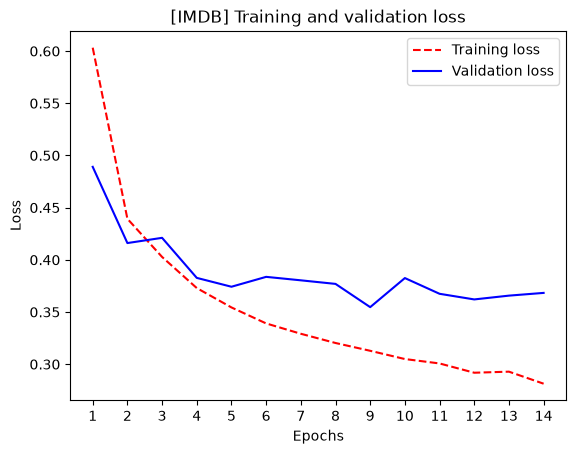

In [ ]:
keras.utils.set_random_seed(42)

inputs = keras.Input(shape=(28*28,), name = "Input_layer")
features_1 = layers.Dense(128, activation="relu", name="Uno",
                          kernel_regularizer=keras.regularizers.L2(1e-4))(inputs)
features_2 = layers.Dense(64, activation="relu",
                          kernel_regularizer=keras.regularizers.L2(1e-4))(features_1)
output = layers.Dense(10, activation="softmax")(features_2)


model = keras.Model(
    inputs = inputs,
    outputs = output,
    name = "Fashion_MNIST_model_mini"
)

print("-----------MODEL SUMMARY-----------")
model.summary()

print("-----------MODEL LAYERS-------------")
for i, layer in enumerate(model.layers):
    print(i, layer.name, layer.__class__.__name__)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor = "val_loss",
    patience=5,
    restore_best_weights=True
)


history = model.fit(
    train_images,
    train_labels,
    epochs=20,
    batch_size=125,
    validation_split=0.2,
    callbacks = [early_stopping]
    )


import matplotlib.pyplot as plt

history_dict = history.history
loss_values = history_dict["loss"]
val_loss_values = history_dict["val_loss"]
epochs = range(1, len(loss_values) + 1)
plt.plot(epochs, loss_values, "r--", label="Training loss")
plt.plot(epochs, val_loss_values, "b", label="Validation loss")
plt.title("[IMDB] Training and validation loss")
plt.xlabel("Epochs")
plt.xticks(epochs)
plt.ylabel("Loss")
plt.legend()
plt.show()

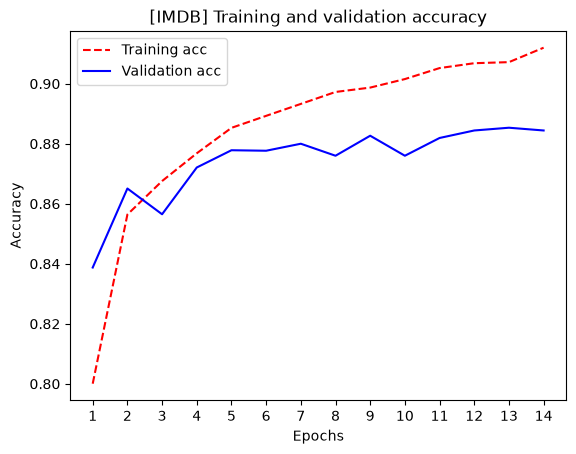

In [7]:
plt.clf()
acc = history_dict["accuracy"]
val_acc = history_dict["val_accuracy"]
plt.plot(epochs, acc, "r--", label="Training acc")
plt.plot(epochs, val_acc, "b", label="Validation acc")
plt.title("[IMDB] Training and validation accuracy")
plt.xlabel("Epochs")
plt.xticks(epochs)
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [8]:
print(f"Ultima training accuracy: "
      f"{history.history['accuracy'][-1]:.2%}")

print(f"Ultima validation accuracy: "
      f"{history.history['val_accuracy'][-1]:.2%}")

print(f"Migliore validation accuracy: "
      f"{max(history.history['val_accuracy']):.2%}")

Ultima training accuracy: 91.20%
Ultima validation accuracy: 88.44%
Migliore validation accuracy: 88.53%


In [9]:
import numpy as np

best_epoch = np.argmin(history.history["val_loss"])

print(f"Epoca migliore: {best_epoch + 1}")
print(
    "Validation loss minima:",
    history.history["val_loss"][best_epoch]
)
print(
    "Validation accuracy in quell'epoca:",
    f"{history.history['val_accuracy'][best_epoch]:.2%}"
)

Epoca migliore: 9
Validation loss minima: 0.35468071699142456
Validation accuracy in quell'epoca: 88.27%


In [10]:
x_val = train_images[48000:]
y_val = train_labels[48000:]

probabilities = model.predict(x_val, verbose=0)

calcola_ce = keras.losses.SparseCategoricalCrossentropy(from_logits=False)

ce = float(calcola_ce(y_val, probabilities))
print("Crossenttopy di validazione:",ce)



Crossenttopy di validazione: 0.31390535831451416


In [11]:
penalita_l2 = sum(float(termine) for termine in model.losses)

print("Penalità L2:", penalita_l2)
print("Crossentropy + L2:", ce + penalita_l2)

Penalità L2: 0.04077536519616842
Crossentropy + L2: 0.3546807235106826
